In [1]:
!pip install -q kaggle
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
!unzip -q skin-cancer-mnist-ham10000.zip -d ham10000
!ls ham10000

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:36<00:00, 155MB/s]

ham10000_images_part_1	HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_images_part_1	HAM10000_metadata.csv	hmnist_8_8_L.csv
ham10000_images_part_2	hmnist_28_28_L.csv	hmnist_8_8_RGB.csv


Toplam görsel: 10015
Farklı lezyon: 7470

Sınıf dağılımı:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


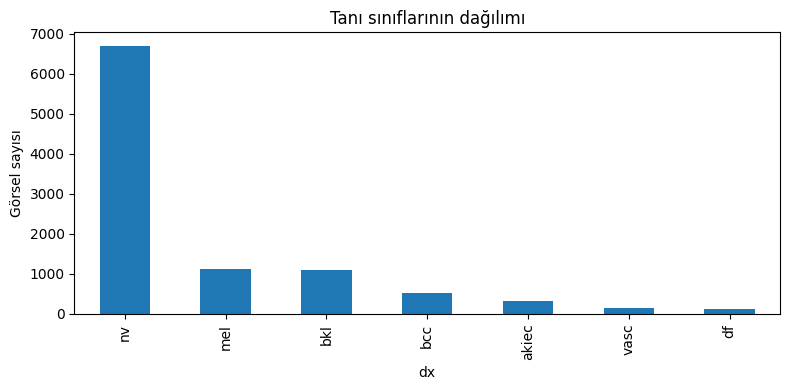

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

meta = pd.read_csv("ham10000/HAM10000_metadata.csv")
print("Toplam görsel:", len(meta))
print("Farklı lezyon:", meta["lesion_id"].nunique())
print("\nSınıf dağılımı:")
print(meta["dx"].value_counts())

meta["dx"].value_counts().plot(kind="bar", figsize=(8, 4), title="Tanı sınıflarının dağılımı")
plt.ylabel("Görsel sayısı")
plt.tight_layout()
plt.savefig("sinif_dagilimi.png", dpi=150)
plt.show()

In [3]:
meta["label"] = meta["dx"].isin(["mel", "bcc", "akiec"]).map({True: "Kötü huylu", False: "İyi huylu"})
print(meta["label"].value_counts())
print(meta["label"].value_counts(normalize=True).round(3))

tekrar = meta.groupby("lesion_id").size()
print("\nBirden fazla fotoğrafı olan lezyon sayısı:", (tekrar > 1).sum())
print("Lezyon başına fotoğraf sayısı dağılımı:")
print(tekrar.value_counts().sort_index())

label
İyi huylu     8061
Kötü huylu    1954
Name: count, dtype: int64
label
İyi huylu     0.805
Kötü huylu    0.195
Name: proportion, dtype: float64

Birden fazla fotoğrafı olan lezyon sayısı: 1956
Lezyon başına fotoğraf sayısı dağılımı:
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64


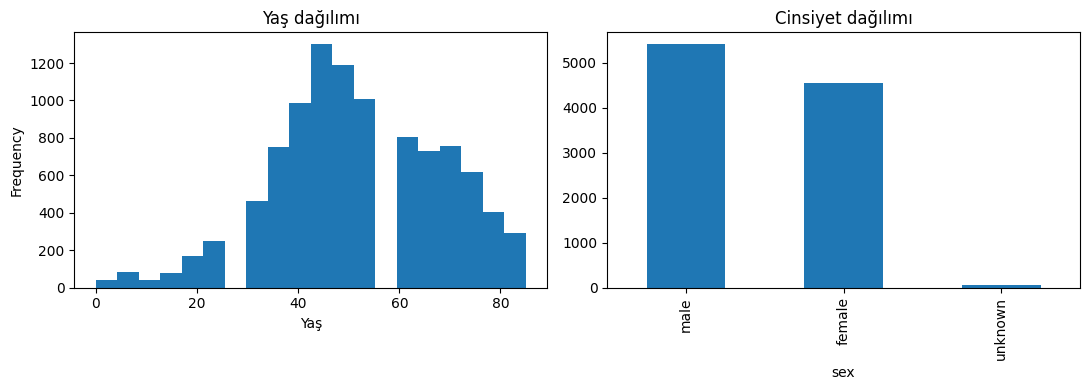

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
meta["age"].plot(kind="hist", bins=20, ax=ax[0], title="Yaş dağılımı")
ax[0].set_xlabel("Yaş")
meta["sex"].value_counts().plot(kind="bar", ax=ax[1], title="Cinsiyet dağılımı")
plt.tight_layout()
plt.savefig("yas_cinsiyet.png", dpi=150)
plt.show()

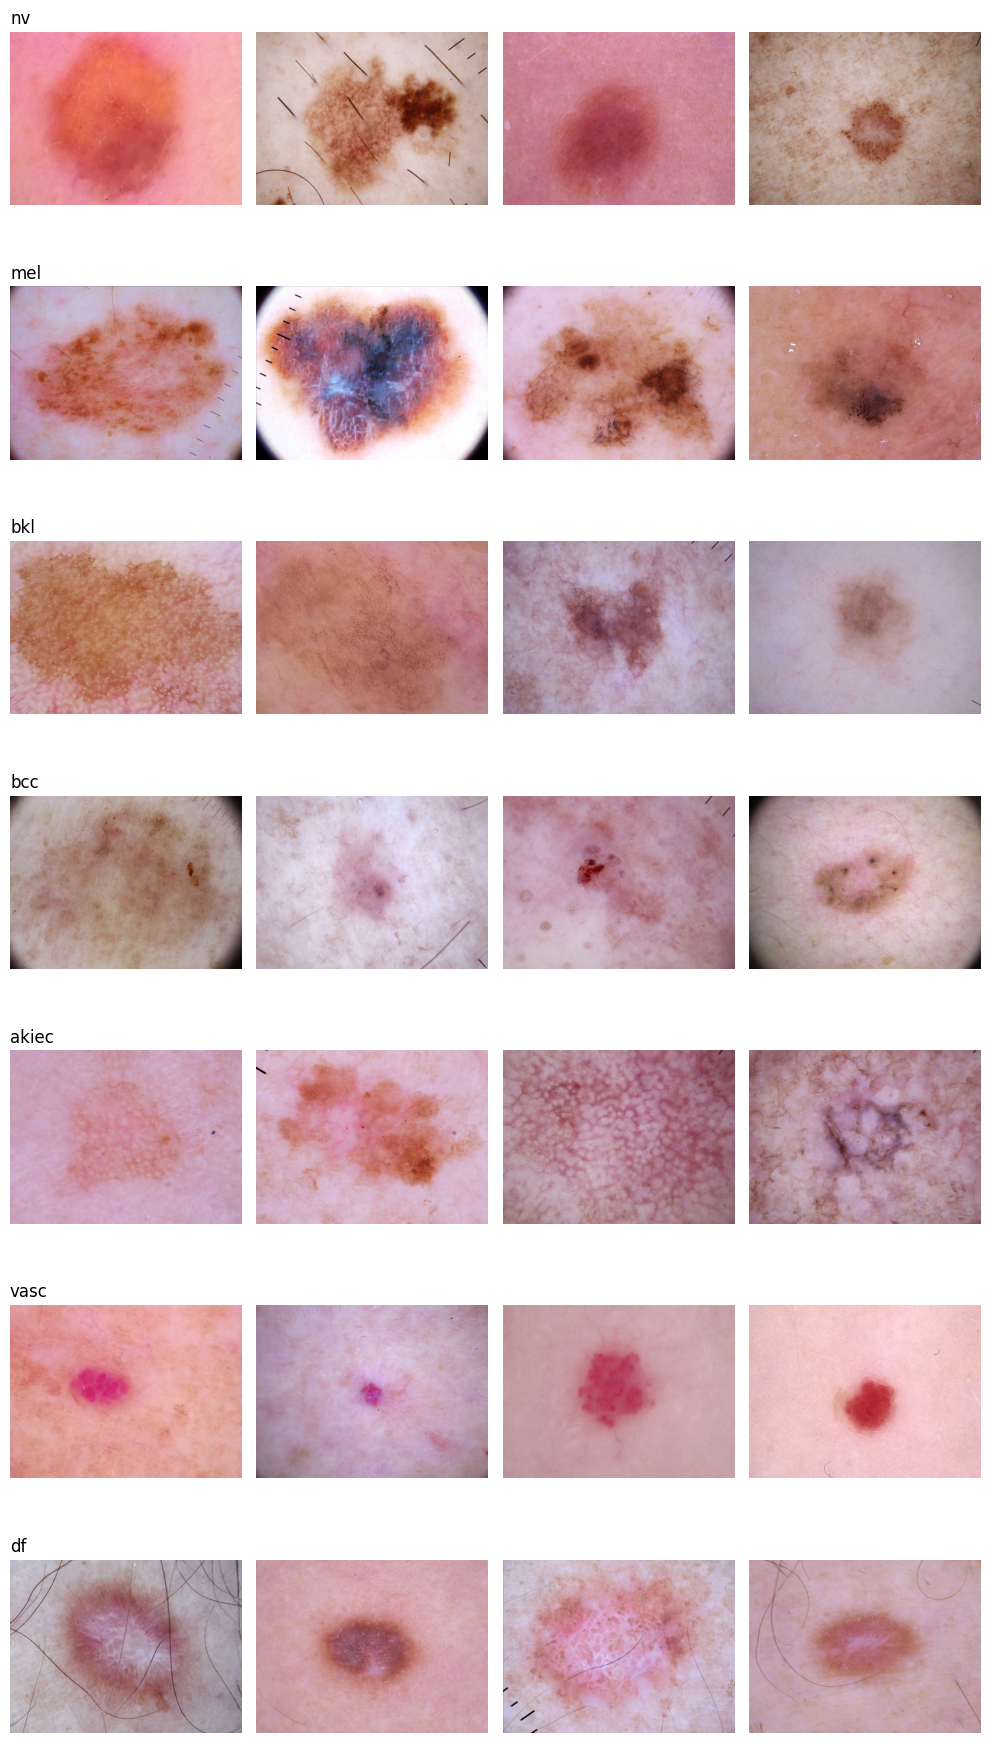

In [5]:
import glob, os
from PIL import Image

yollar = {os.path.splitext(os.path.basename(p))[0]: p
          for p in glob.glob("ham10000/**/*.jpg", recursive=True)}
siniflar = meta["dx"].value_counts().index
fig, axes = plt.subplots(len(siniflar), 4, figsize=(10, 2.6 * len(siniflar)))
for i, s in enumerate(siniflar):
    ornek = meta[meta["dx"] == s].sample(4, random_state=42)
    for j, img_id in enumerate(ornek["image_id"]):
        axes[i, j].imshow(Image.open(yollar[img_id]))
        axes[i, j].axis("off")
    axes[i, 0].set_title(s, loc="left")
plt.tight_layout()
plt.savefig("ornek_gorseller.png", dpi=120)
plt.show()